# Predicting Electricity Consumption and Detecting Anomalous Energy Use

This notebook develops a simple machine-learning workflow for university-building electricity data.

We will work mainly with the **GEPIII / ASHRAE Energy Prediction** dataset.

The notebook has two main phases:

**Phase 1 — Electricity prediction**
- Clean and prepare the data
- Explore electricity consumption
- Create simple time, building and weather features
- Build a **Linear Regression base model**
- Build **Random Forest** and **Gradient Boosting proposed models**
- Compare the models using MAE, RMSE and R²

**Phase 2 — Anomaly detection**
- Calculate prediction residuals
- Identify unusually large residuals
- Rank unusual observations by their prediction error

The official GEPIII test set is kept separate because its actual electricity readings are not provided.

## Status and change log (edited version for Person A)

This notebook is the submitted one with **only the changes the new plan needs**. Every changed or new code cell starts with a `# CHANGED` or `# NEW` comment that says what was changed and why; markdown cells that changed end with an italic `(CHANGED: ...)` note. Old code that was replaced is kept as `# OLD` comments.

| Where | What changed | Why |
|---|---|---|
| Section 8.1 (NEW) | Long runs of exact zeros are treated as sensor dropout and removed; a complete hourly grid is built | Zeros are not real low use; the grid is needed for correct lags |
| Section 11 | `month` removed from `features`; the whole-dataset median fill removed | Test months are never seen in training; the fill leaked information from the future |
| Section 13 | Split by fixed dates into train / validation / test | One global time cut, plus a separate test period |
| Section 14 | Unchanged (its text now says "five" features) | The training-only fill is now the only fill |
| Section 22 (exploration of row-based lags and gaps) | Unchanged | It shows the problem the fix solves |
| Section 22.1 (cell after the gap analysis) | Lags built by time on the hourly grid, plus `lag_2h`, `lag_3h`, `roll_24h`, with tests | Row-based shifts were wrong wherever hours are missing |
| Section 22 (lag model) | `month` removed; split by date instead of by row; period and anomaly cells use the date masks | The old cut put different buildings, not a later period, in validation |
| Section 23 (NEW) | Same-as-last-hour and historical typical predictors, feature sets A to D with one model, accuracy table, saved files | Plan Step 6 and the hand-off to Person B |
| All cells | Saved outputs were cleared | They came from the old pipeline; re-run the notebook |

**Unchanged on purpose:** sections 1 to 10, 14 to 21, the lag exploration cells, the random forest with lags, and the residual cells at the end. The residual and anomaly sections (17 to 21 and the cells after the lag model) and the final *Observation* text are the **submission-stage** global-threshold method; they are kept for the record and are replaced by Person B's per-building thresholds, so do not report their flag counts as findings.

**Hand-off files (written in section 23):** `../outputs/hourly_table.parquet`, `../outputs/predictions.parquet`, `../outputs/zero_run_hours.parquet`, `../outputs/run_log_personA.json`, `../outputs/table1_test_accuracy.csv`. Column names follow this notebook (`meter_reading` is the cleaned target; lags are `lag_1h`, `lag_2h`, `lag_3h`, `lag_24h`, `lag_168h`, `roll_24h`).

## 1. Import libraries

We use common Python libraries and keep the code simple so each step is easy to follow.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 2. Load the GEPIII data

In [ ]:
train = pd.read_csv("../Data/train.csv")
test = pd.read_csv("../Data/test.csv")
building_metadata = pd.read_csv("../Data/building_metadata.csv")
weather_train = pd.read_csv("../Data/weather_train.csv")
weather_test = pd.read_csv("../Data/weather_test.csv")
sample_submission = pd.read_csv("../Data/sample_submission.csv")

## 3. Structure of all the data

In [ ]:
print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Building metadata shape:", building_metadata.shape)
print("Weather train shape:", weather_train.shape)
print("Weather test shape:", weather_test.shape)

Train shape: (20216100, 4)
Test shape: (41697600, 4)
Building metadata shape: (1449, 6)
Weather train shape: (139773, 9)
Weather test shape: (277243, 9)


In [ ]:
print(train.head())
print(train.columns)

print(building_metadata.head())
print(weather_train.head())

   building_id  meter            timestamp  meter_reading
0            0      0  2016-01-01 00:00:00            0.0
1            1      0  2016-01-01 00:00:00            0.0
2            2      0  2016-01-01 00:00:00            0.0
3            3      0  2016-01-01 00:00:00            0.0
4            4      0  2016-01-01 00:00:00            0.0
Index(['building_id', 'meter', 'timestamp', 'meter_reading'], dtype='str')
   site_id  building_id primary_use  square_feet  year_built  floor_count
0        0            0   Education         7432      2008.0          NaN
1        0            1   Education         2720      2004.0          NaN
2        0            2   Education         5376      1991.0          NaN
3        0            3   Education        23685      2002.0          NaN
4        0            4   Education       116607      1975.0          NaN
   site_id            timestamp  air_temperature  cloud_coverage  \
0        0  2016-01-01 00:00:00             25.0             6.0 

## 4. Select electricity data

GEPIII contains several meter types. Meter `0` represents electricity so we select that for our project

In [ ]:
electricity = train[train["meter"] == 0].copy()

print("Electricity data shape:", electricity.shape)
print(electricity.head())

Electricity data shape: (12060910, 4)
   building_id  meter            timestamp  meter_reading
0            0      0  2016-01-01 00:00:00            0.0
1            1      0  2016-01-01 00:00:00            0.0
2            2      0  2016-01-01 00:00:00            0.0
3            3      0  2016-01-01 00:00:00            0.0
4            4      0  2016-01-01 00:00:00            0.0


## 5. Convert timestamps

In [ ]:
electricity["timestamp"] = pd.to_datetime(electricity["timestamp"])

weather_train["timestamp"] = pd.to_datetime(weather_train["timestamp"])
weather_test["timestamp"] = pd.to_datetime(weather_test["timestamp"])

test["timestamp"] = pd.to_datetime(test["timestamp"])

## 6. Data cleaning

In [ ]:
# Check exact duplicate rows
print("Exact duplicate rows:", electricity.duplicated().sum())

# Check duplicate building/timestamp/meter records
print("Duplicate building-timestamp-meter rows:", electricity.duplicated( subset=["building_id", "timestamp", "meter"]).sum())

# Check negative readings
print("Negative meter readings:", (electricity["meter_reading"] < 0).sum())

# Check missing target readings
print("Missing meter readings:", electricity["meter_reading"].isna().sum())

Exact duplicate rows: 0
Duplicate building-timestamp-meter rows: 0
Negative meter readings: 0
Missing meter readings: 0


### 6.1 Remove duplicate records

In [ ]:
before = len(electricity)

# Remove exact duplicates
electricity = electricity.drop_duplicates().copy()

# Remove duplicate building/timestamp/meter observations
electricity = electricity.drop_duplicates(subset=["building_id", "timestamp", "meter"],keep="first").copy()

print("Rows removed because of duplicates:", before - len(electricity))
print("Rows remaining:", len(electricity))

Rows removed because of duplicates: 0
Rows remaining: 12060910


### 6.2 Handle invalid negative readings

In [ ]:
before = len(electricity)

electricity = electricity[electricity["meter_reading"] >= 0].copy()

print("Negative readings removed:", before - len(electricity))
print("Rows remaining:", len(electricity))

Negative readings removed: 0
Rows remaining: 12060910


### 6.3 Handle missing target readings

In [ ]:
before = len(electricity)

electricity = electricity.dropna(subset=["meter_reading"]).copy()

print("Rows removed because target was missing:", before - len(electricity))
print("Missing target values remaining:", electricity["meter_reading"].isna().sum())

Rows removed because target was missing: 0
Missing target values remaining: 0


## 7. Create basic time features

Electricity use can change depending on the hour, day of the week, month and whether it is a weekend.

In [ ]:
electricity["hour"] = electricity["timestamp"].dt.hour
electricity["dayofweek"] = electricity["timestamp"].dt.dayofweek
electricity["month"] = electricity["timestamp"].dt.month
electricity["weekend"] = (electricity["dayofweek"] >= 5).astype(int)

## 8. Exploratory data analysis

These plots help us understand the electricity data before modelling.

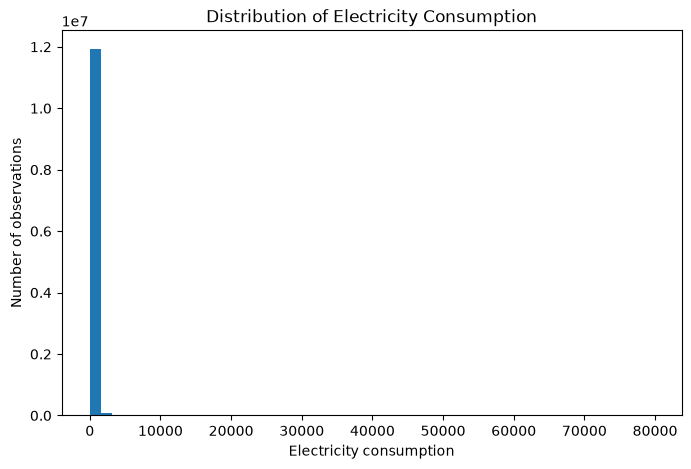

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(electricity["meter_reading"], bins=50)
plt.xlabel("Electricity consumption")
plt.ylabel("Number of observations")
plt.title("Distribution of Electricity Consumption")
plt.show()

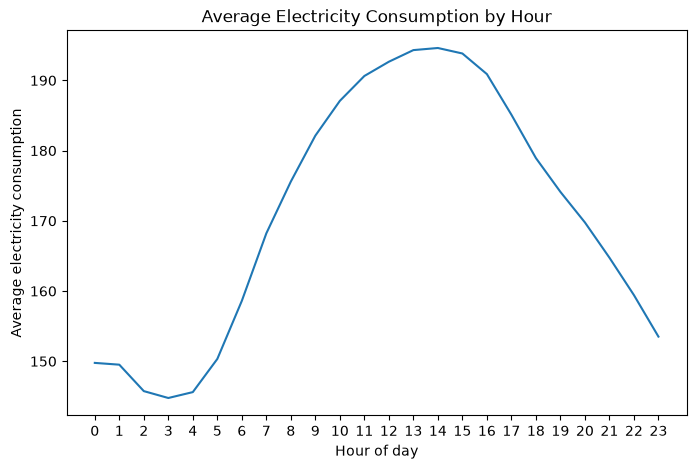

In [ ]:
hourly_average = electricity.groupby("hour")["meter_reading"].mean()

plt.figure(figsize=(8, 5))
plt.plot(hourly_average.index, hourly_average.values)
plt.xlabel("Hour of day")
plt.ylabel("Average electricity consumption")
plt.title("Average Electricity Consumption by Hour")
plt.xticks(range(24))
plt.show()

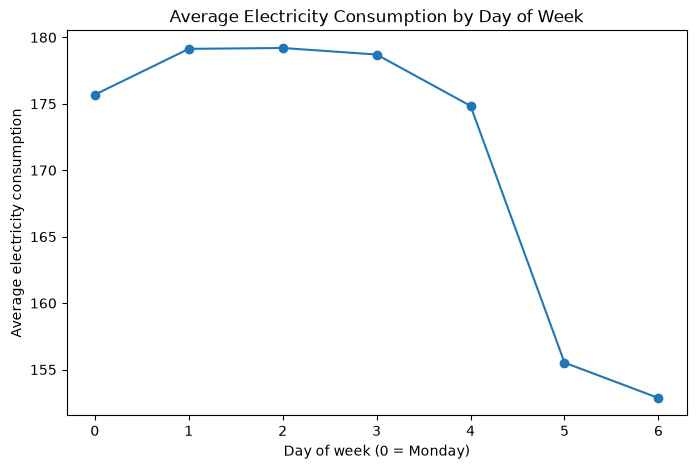

In [ ]:
weekday_average = electricity.groupby("dayofweek")["meter_reading"].mean()

plt.figure(figsize=(8, 5))
plt.plot(weekday_average.index, weekday_average.values, marker="o")
plt.xlabel("Day of week (0 = Monday)")
plt.ylabel("Average electricity consumption")
plt.title("Average Electricity Consumption by Day of Week")
plt.show()

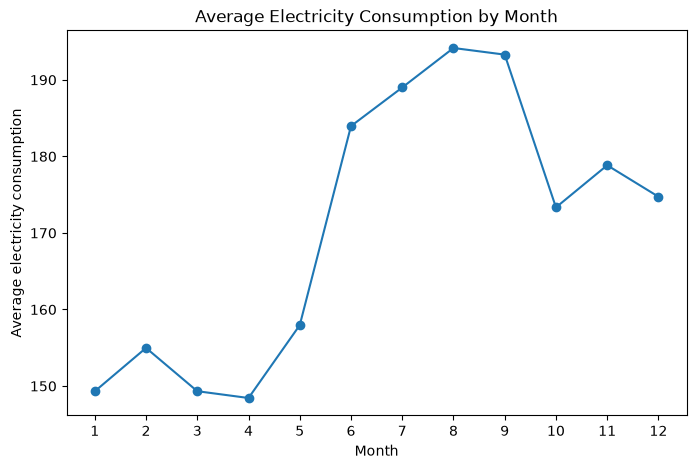

In [ ]:
monthly_average = electricity.groupby("month")["meter_reading"].mean()

plt.figure(figsize=(8, 5))
plt.plot(monthly_average.index, monthly_average.values, marker="o")
plt.xlabel("Month")
plt.ylabel("Average electricity consumption")
plt.title("Average Electricity Consumption by Month")
plt.xticks(range(1, 13))
plt.show()

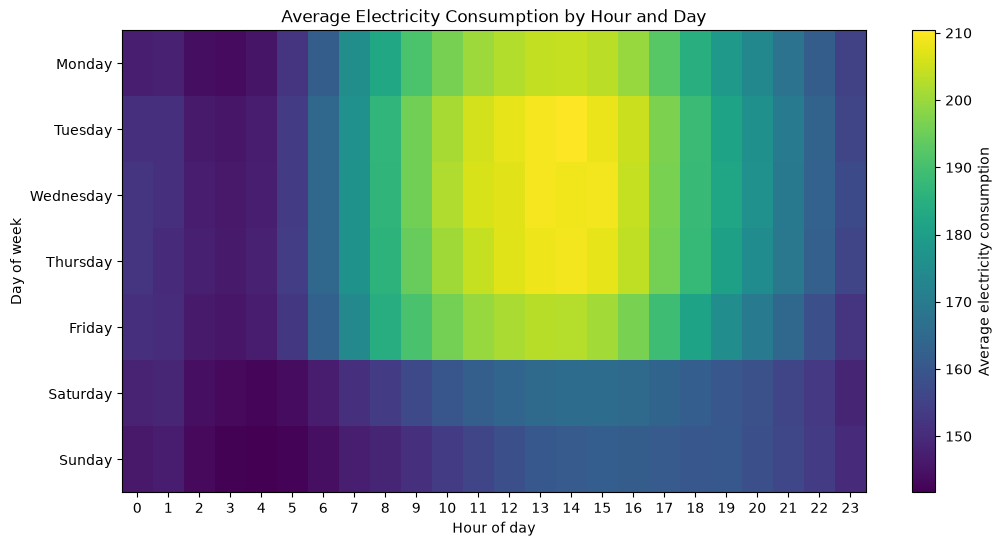

In [ ]:
# Average electricity consumption by hour and day of week

heatmap_data = electricity.pivot_table(values="meter_reading", index="dayofweek", columns="hour", aggfunc="mean")
# Rename the days for easier reading
heatmap_data.index = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
plt.figure(figsize=(12, 6))
plt.imshow(heatmap_data, aspect="auto")
plt.colorbar(label="Average electricity consumption")
plt.xlabel("Hour of day")
plt.ylabel("Day of week")
plt.title("Average Electricity Consumption by Hour and Day")
plt.xticks(range(24))
plt.yticks(range(7), heatmap_data.index)
plt.show()

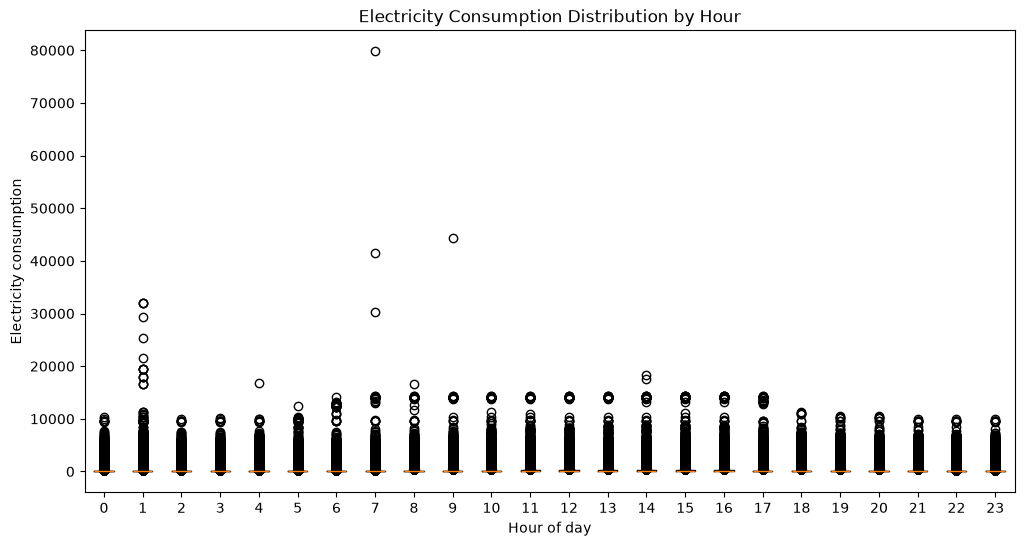

In [ ]:
# Electricity consumption distribution by hour

hourly_data = []

for hour in range(24):
    values = electricity[electricity["hour"] == hour]["meter_reading"]
    hourly_data.append(values)

plt.figure(figsize=(12, 6))
plt.boxplot(hourly_data)
plt.xlabel("Hour of day")
plt.ylabel("Electricity consumption")
plt.title("Electricity Consumption Distribution by Hour")
plt.xticks(range(1, 25), range(24))
plt.show()

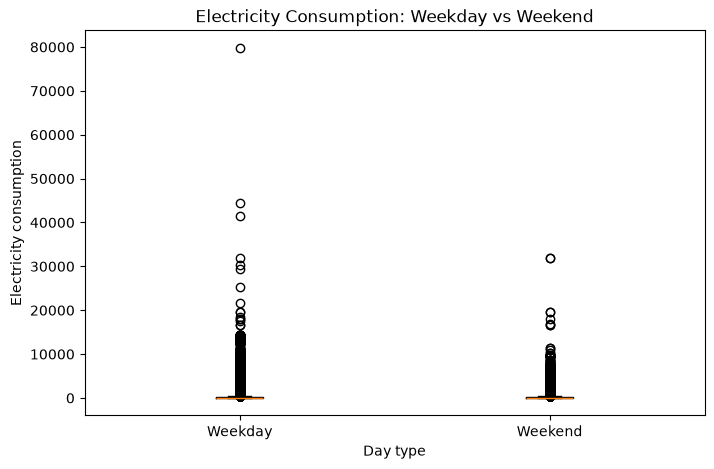

In [ ]:
# Compare weekday and weekend electricity consumption

weekday_data = electricity[electricity["weekend"] == 0]["meter_reading"]
weekend_data = electricity[electricity["weekend"] == 1]["meter_reading"]
plt.figure(figsize=(8, 5))
plt.boxplot([weekday_data, weekend_data],tick_labels=["Weekday", "Weekend"])
plt.xlabel("Day type")
plt.ylabel("Electricity consumption")
plt.title("Electricity Consumption: Weekday vs Weekend")
plt.show()

## 8.1 Treat long zero runs as sensor dropout (NEW)

Some buildings show exactly zero for many hours in a row. A real building rarely uses exactly zero electricity for a day, so this is usually a sensor dropout, not real low use. We treat runs of 24 or more zeros as missing and remove those hours. The same cell builds the **complete hourly grid** (every building for every hour of 2016) that the corrected lag features in section 22.1 use.

In [ ]:
# NEW (plan Step 2): treat long runs of exact zeros as sensor dropout (missing), not as real low use.
# Why: if zeros stay in the data the model learns that "zero" is normal. Rule: >= ZERO_RUN_MIN_HOURS consecutive zeros
# (a missing gap of up to 3 hours between zeros does not split a run). The masked hours are removed from `electricity`,
# so the merge, the split and every model below exclude them. EDA above is deliberately left as submitted.
# The cell also builds the complete hourly grid (every building x every hour of 2016) reused for the lags in section 22.1.
from pathlib import Path
import json
RUN_LOG = {}                                   # numbers for the report, saved at the end of section 23

HOURS = pd.date_range("2016-01-01 00:00", "2016-12-31 23:00", freq=pd.Timedelta(hours=1))
N_HOURS = len(HOURS)                           # 8,784 (2016 is a leap year)
ZERO_RUN_MIN_HOURS = 24                        # write the final value in the report
assert electricity["timestamp"].between(HOURS[0], HOURS[-1]).all(), "readings outside the 2016 grid"

bids = np.sort(electricity["building_id"].unique())
grid_idx = pd.MultiIndex.from_product([bids, HOURS], names=["building_id", "timestamp"])
reading_grid = electricity.set_index(["building_id", "timestamp"])["meter_reading"].reindex(grid_idx)
Y = reading_grid.to_numpy(dtype="float64").reshape(len(bids), N_HOURS)

def runs(mask):
    d = np.diff(np.concatenate([[0], mask.astype(np.int8), [0]]))
    return np.flatnonzero(d == 1), np.flatnonzero(d == -1)      # start (inclusive), end (exclusive)

zero_mask = np.zeros(Y.shape, dtype=bool)
for i in range(len(bids)):
    z = Y[i] == 0
    cand = z.copy()
    for a, b in zip(*runs(np.isnan(Y[i]))):                     # bridge missing gaps of <= 3 h between zeros
        if b - a <= 3 and a > 0 and b < N_HOURS and z[a - 1] and z[b]:
            cand[a:b] = True
    for a, b in zip(*runs(cand)):
        if b - a >= ZERO_RUN_MIN_HOURS:
            zero_mask[i, a:b] = z[a:b]

Y_clean = Y.copy()
Y_clean[zero_mask] = np.nan                                      # cleaned grid, reused in section 22.1
zero_run_hours = reading_grid.index[zero_mask.reshape(-1)].to_frame(index=False)

before = len(electricity)
key = pd.MultiIndex.from_frame(electricity[["building_id", "timestamp"]])
electricity = electricity[~key.isin(pd.MultiIndex.from_frame(zero_run_hours))].copy()

print("Zero-run hours removed:", before - len(electricity))
print("Buildings affected:", int(zero_mask.any(axis=1).sum()), "of", len(bids))
print("Rows remaining:", len(electricity))
RUN_LOG["zero_runs"] = {"min_run_hours": ZERO_RUN_MIN_HOURS, "hours_removed": int(before - len(electricity)),
                        "buildings_affected": int(zero_mask.any(axis=1).sum()), "buildings_total": int(len(bids))}

Zero-run hours removed: 484006
Buildings affected: 385 of 1413
Rows remaining: 11576904


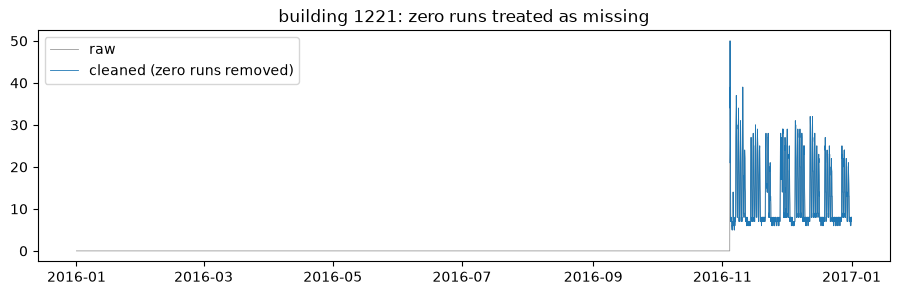

In [ ]:
# NEW (diagnostic): the building with the most removed zero-run hours, raw versus cleaned.
# Look at it (and a few others) and decide whether 24 hours is a sensible limit.
if len(zero_run_hours):
    b = zero_run_hours["building_id"].value_counts().index[0]
    i = int(np.where(bids == b)[0][0])
    plt.figure(figsize=(11, 3))
    plt.plot(HOURS, Y[i], linewidth=0.6, color="0.6", label="raw")
    plt.plot(HOURS, Y_clean[i], linewidth=0.6, label="cleaned (zero runs removed)")
    plt.title(f"building {b}: zero runs treated as missing")
    plt.legend()
    plt.show()

## 9. Merge building and weather information

In [ ]:
data = electricity.merge(building_metadata, on="building_id", how="left")

data = data.merge(weather_train, on=["site_id", "timestamp"], how="left")

print("Merged data shape:", data.shape)

Merged data shape: (11576904, 20)


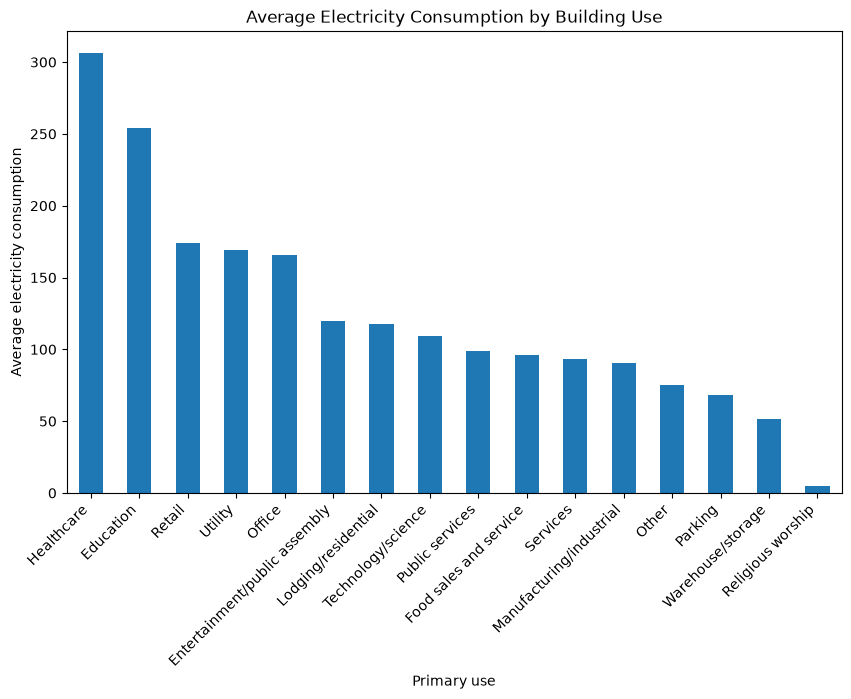

In [ ]:
# Average electricity consumption by building type

building_type_average = (data.groupby("primary_use")["meter_reading"].mean().sort_values(ascending=False))
plt.figure(figsize=(10, 6))
building_type_average.plot(kind="bar")
plt.xlabel("Primary use")
plt.ylabel("Average electricity consumption")
plt.title("Average Electricity Consumption by Building Use")
plt.xticks(rotation=45, ha="right")
plt.show()

## 10. Check missing values after merging

In [ ]:
missing = data.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)

print(missing)

floor_count           8654797
year_built            6348424
cloud_coverage        5105379
precip_depth_1_hr     2489667
sea_level_pressure    1006550
wind_direction         656042
wind_speed              65720
dew_temperature         48049
air_temperature         46332
dtype: int64


## 11. Handle missing feature values

In [ ]:
# CHANGED (plan Step 3): "month" removed from the feature list.
# Why: the data covers one year and the time split (section 13) now puts Nov-Dec in validation/test, so those months
# never appear in training; weather already carries the seasons. The "month" column itself is still created for the EDA.
# OLD: features = ["hour", "dayofweek", "month", "weekend", "air_temperature", "square_feet"]
features = ["hour", "dayofweek", "weekend", "air_temperature", "square_feet"]

# Check that the selected features exist
print("Features:", features)

# Show missing values before filling
print("Missing values before filling:")
print(data[features].isna().sum())

Features: ['hour', 'dayofweek', 'weekend', 'air_temperature', 'square_feet']
Missing values before filling:
hour                   0
dayofweek              0
weekend                0
air_temperature    46332
square_feet            0
dtype: int64


In [ ]:
# CHANGED (plan Step 4): the whole-dataset median fill is removed.
# Why: the medians were computed over ALL rows (training + validation), so information from the future leaked into
# the features (data leakage). The fill now happens only in section 14, using medians from the TRAINING rows only.
# OLD (removed):
# for column in features:
#     median_value = data[column].median()
#     data[column] = data[column].fillna(median_value)

print("Missing values (not filled here any more; filled from training rows only in section 14):")
print(data[features].isna().sum())

Missing values (not filled here any more; filled from training rows only in section 14):
hour                   0
dayofweek              0
weekend                0
air_temperature    46332
square_feet            0
dtype: int64


### 11.1 Final data-quality check

In [ ]:
print("Missing target:", data["meter_reading"].isna().sum())
print("Negative target values:", (data["meter_reading"] < 0).sum())

print("Duplicate building-timestamp-meter rows:", data.duplicated(subset=["building_id", "timestamp", "meter"]).sum())

print("Final modelling rows:", len(data))

Missing target: 0
Negative target values: 0
Duplicate building-timestamp-meter rows: 0
Final modelling rows: 11576904


## 12. Sort the data by time

In [ ]:
data = data.sort_values("timestamp").reset_index(drop=True)

## 13. Train/validation split

We need labelled data to evaluate our models.

The official GEPIII `test.csv` does not contain the actual `meter_reading`, so we cannot use it to calculate MAE, RMSE or R².

Instead, we split the labelled data **by time** into three periods: train (before 2016-09-13, about 70%), validation (2016-09-13 to 2016-11-06, about 15%) and test (from 2016-11-07, about 15%).

*(CHANGED: this was "the last 20% of the labelled data" as validation. A fixed date cut gives the same split for every building, adds a separate test period, and is the split used for everything below.)*

This is preferable to a random split because a random split can mix future observations into the training data.

In [ ]:
# CHANGED (plan Step 3): time split by fixed dates, three periods, instead of the last 20% of rows.
# Why: one global cut in time for every building and every model, with a separate test period that is touched only
# for the final numbers (validation is used for choosing models and, later, thresholds).
# OLD:
# split_index = int(len(data) * 0.80)
# train_data = data.iloc[:split_index].copy()
# valid_data = data.iloc[split_index:].copy()
TRAIN_END = pd.Timestamp("2016-09-13")      # train: timestamp <  TRAIN_END
VAL_END = pd.Timestamp("2016-11-07")        # validation: TRAIN_END <= timestamp < VAL_END ; test: timestamp >= VAL_END

train_data = data[data["timestamp"] < TRAIN_END].copy()
valid_data = data[(data["timestamp"] >= TRAIN_END) & (data["timestamp"] < VAL_END)].copy()
test_data = data[data["timestamp"] >= VAL_END].copy()

# check: train ends before validation starts, validation ends before test starts
assert train_data["timestamp"].max() < valid_data["timestamp"].min()
assert valid_data["timestamp"].max() < test_data["timestamp"].min()

print("Training rows:", len(train_data))
print("Validation rows:", len(valid_data))
print("Test rows:", len(test_data))

print("Training period:", train_data["timestamp"].min(), "to", train_data["timestamp"].max())
print("Validation period:", valid_data["timestamp"].min(), "to", valid_data["timestamp"].max())
print("Test period:", test_data["timestamp"].min(), "to", test_data["timestamp"].max())

Training rows: 7956566
Validation rows: 1809634
Test rows: 1810704
Training period: 2016-01-01 00:00:00 to 2016-09-12 23:00:00
Validation period: 2016-09-13 00:00:00 to 2016-11-06 23:00:00
Test period: 2016-11-07 00:00:00 to 2016-12-31 23:00:00


## 14. Prepare model inputs

We use the same five simple features for all three models so that the comparison is fair.

The missing-value medians are calculated from the training period only and then applied to both training and validation data.

*(CHANGED: "six" became "five" because month was removed from the features, see section 11. The training-only median fill described here is now the only fill, because the whole-dataset fill was removed.)*

In [ ]:
X_train = train_data[features].copy()
X_valid = valid_data[features].copy()

y_train = train_data["meter_reading"]
y_valid = valid_data["meter_reading"]

# Calculate medians only from the training data
train_medians = X_train.median()

for column in features:
    X_train[column] = X_train[column].fillna(train_medians[column])
    X_valid[column] = X_valid[column].fillna(train_medians[column])

print("Missing values in X_train:")
print(X_train.isna().sum())

print("Missing values in X_valid:")
print(X_valid.isna().sum())

Missing values in X_train:
hour               0
dayofweek          0
weekend            0
air_temperature    0
square_feet        0
dtype: int64
Missing values in X_valid:
hour               0
dayofweek          0
weekend            0
air_temperature    0
square_feet        0
dtype: int64


# 15. Build the models

### Base model: Linear Regression

### Proposed model 1: Random Forest

### Proposed model 2: Gradient Boosting

In [ ]:
# 1. Base Model: Linear Regression
base_model = LinearRegression()
base_model.fit(X_train, y_train)

base_pred = base_model.predict(X_valid)


# 2. Proposed Model: Random Forest
rf_model = RandomForestRegressor(n_estimators=50, max_depth=12, min_samples_leaf=5, random_state=42, n_jobs=2)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_valid)


# 3. Proposed Model: Gradient Boosting
gb_model = GradientBoostingRegressor(n_estimators=100, learning_rate=0.05, max_depth=3, random_state=42)

gb_model.fit(X_train, y_train)

gb_pred = gb_model.predict(X_valid)

## 16. Compare the three models

In [ ]:
model_predictions = {"Linear Regression (Base)": base_pred, "Random Forest (Proposed)": rf_pred, "Gradient Boosting (Proposed)": gb_pred}

results = []

for model_name, predictions in model_predictions.items():
    mae = mean_absolute_error(y_valid, predictions)
    rmse = np.sqrt(mean_squared_error(y_valid, predictions))
    r2 = r2_score(y_valid, predictions)

    results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))

                       Model        MAE       RMSE       R2
    Linear Regression (Base) 130.505574 307.684200 0.323484
    Random Forest (Proposed)  64.704310 177.323910 0.775300
Gradient Boosting (Proposed) 114.890631 256.785261 0.528797


### 16.1 Visual comparison

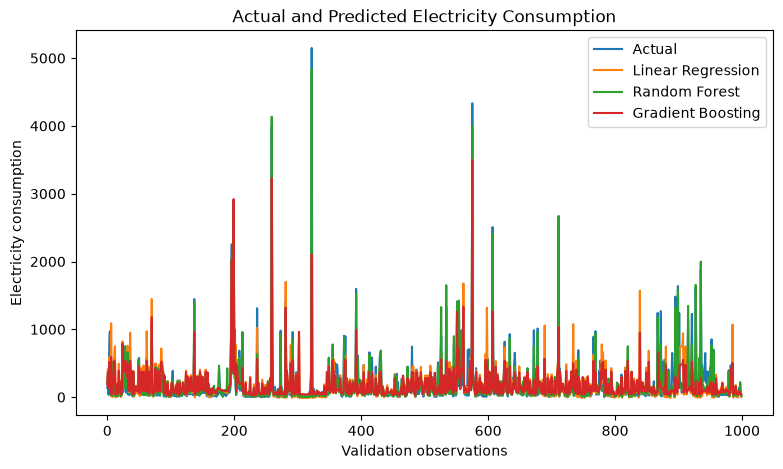

In [ ]:
plt.figure(figsize=(9, 5))

sample_size = min(1000, len(y_valid))
sample_index = np.arange(sample_size)

plt.plot(sample_index, y_valid.iloc[:sample_size].values, label="Actual")
plt.plot(sample_index, base_pred[:sample_size], label="Linear Regression")
plt.plot(sample_index, rf_pred[:sample_size], label="Random Forest")
plt.plot(sample_index, gb_pred[:sample_size], label="Gradient Boosting")

plt.xlabel("Validation observations")
plt.ylabel("Electricity consumption")
plt.title("Actual and Predicted Electricity Consumption")
plt.legend()
plt.show()

## 17. Select a proposed model for residual analysis

In [ ]:
rf_rmse = np.sqrt(mean_squared_error(y_valid, rf_pred))
gb_rmse = np.sqrt(mean_squared_error(y_valid, gb_pred))

if rf_rmse <= gb_rmse:
    chosen_model_name = "Random Forest"
    chosen_predictions = rf_pred
else:
    chosen_model_name = "Gradient Boosting"
    chosen_predictions = gb_pred

print("Model used for residual analysis:", chosen_model_name)

Model used for residual analysis: Random Forest


## 18. Calculate prediction residuals

In [ ]:
validation_results = valid_data[
    ["timestamp", "building_id", "site_id", "meter_reading"]
].copy()

validation_results["predicted"] = chosen_predictions
validation_results["residual"] = (
    validation_results["meter_reading"]
    - validation_results["predicted"]
)

validation_results["absolute_error"] = (
    validation_results["residual"].abs()
)

validation_results.head()

,timestamp,building_id,site_id,meter_reading,predicted,residual,absolute_error
7956566,2016-09-13,951,9,134.0,209.028185,-75.028185,75.028185
7956567,2016-09-13,952,9,199.0,355.909515,-156.909515,156.909515
7956568,2016-09-13,956,9,35.0,146.077939,-111.077939,111.077939
7956569,2016-09-13,954,9,751.0,512.894516,238.105484,238.105484
7956570,2016-09-13,955,9,970.0,441.371533,528.628467,528.628467


## 19. Simple residual-based anomaly detection

In [ ]:
residual_mean = validation_results["residual"].mean()
residual_std = validation_results["residual"].std()

upper_threshold = residual_mean + 3 * residual_std
lower_threshold = residual_mean - 3 * residual_std

validation_results["anomaly"] = (
    (validation_results["residual"] > upper_threshold) |
    (validation_results["residual"] < lower_threshold)
)

print("Number of flagged anomalies:", validation_results["anomaly"].sum())
print("Percentage flagged:", validation_results["anomaly"].mean() * 100)

Number of flagged anomalies: 19867
Percentage flagged: 1.0978463048329108


## 20. Rank the most unusual observations

In [ ]:
top_anomalies = validation_results.sort_values(
    "absolute_error",
    ascending=False
).head(20)

top_anomalies

,timestamp,building_id,site_id,meter_reading,predicted,residual,absolute_error,anomaly
9081691,2016-10-17 07:00:00,993,9,79769.0,1311.527567,78457.472433,78457.472433,True
9081694,2016-10-17 07:00:00,954,9,41552.0,512.894516,41039.105484,41039.105484,True
9044057,2016-10-16 01:00:00,993,9,31921.0,1390.698162,30530.301838,30530.301838,True
9013905,2016-10-15 01:00:00,993,9,31921.0,1390.698162,30530.301838,30530.301838,True
9074171,2016-10-17 01:00:00,993,9,31921.0,1395.066272,30525.933728,30525.933728,True
9081695,2016-10-17 07:00:00,904,9,30268.0,513.414904,29754.585096,29754.585096,True
9652522,2016-11-03 14:00:00,799,7,17502.1,909.101747,16592.998253,16592.998253,True
9074178,2016-10-17 01:00:00,954,9,16539.0,512.894516,16026.105484,16026.105484,True
9044064,2016-10-16 01:00:00,954,9,16539.0,512.894516,16026.105484,16026.105484,True
9013912,2016-10-15 01:00:00,954,9,16539.0,512.894516,16026.105484,16026.105484,True


## 21. Inspect the residuals

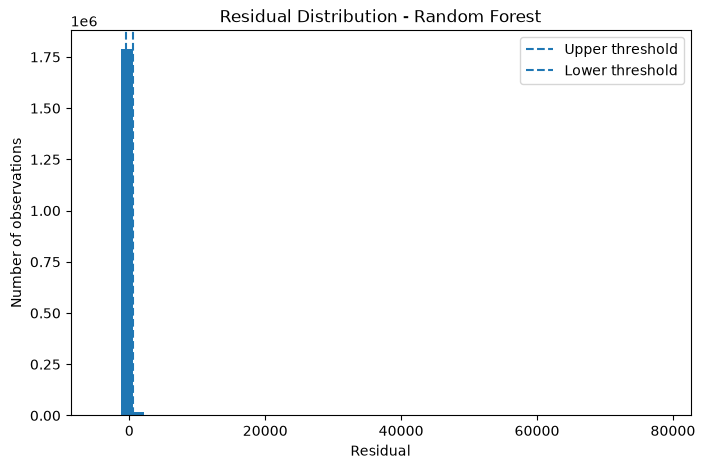

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(validation_results["residual"], bins=50)
plt.axvline(upper_threshold, linestyle="--", label="Upper threshold")
plt.axvline(lower_threshold, linestyle="--", label="Lower threshold")
plt.xlabel("Residual")
plt.ylabel("Number of observations")
plt.title(f"Residual Distribution - {chosen_model_name}")
plt.legend()
plt.show()

## 22. Historical feature engineering

The next step improves the model by adding lag-based historical features. Electricity demand is strongly time dependent, so including the previous hour, the same hour from the previous day, and the same hour from the previous week helps the model understand recurring demand patterns.

### Why these lag features?

- Previous hour: captures short-term demand changes.
- Previous day at the same hour: captures daily recurring demand cycles.
- Previous week at the same hour: captures weekly seasonal patterns.

These lag variables are useful because building electricity use is often highly time-dependent and repetitive.

In [ ]:
#  Historical Feature Engineering

# Make a copy so we don't accidentally modify the original dataframe
elec_df = electricity.copy()

# Sort by building and time
elec_df = elec_df.sort_values(
    ["building_id", "timestamp"]
).reset_index(drop=True)

# Check the result
elec_df[["building_id", "timestamp", "meter_reading"]].head(10)

,building_id,timestamp,meter_reading
0,0,2016-01-30 08:00:00,43.6839
1,0,2016-01-30 09:00:00,0.0000
2,0,2016-01-30 10:00:00,0.0000
3,0,2016-01-30 11:00:00,0.0000
4,0,2016-01-30 12:00:00,0.0000
5,0,2016-01-30 13:00:00,0.0000
6,0,2016-01-30 14:00:00,0.0000
7,0,2016-01-30 15:00:00,0.0000
8,0,2016-01-30 16:00:00,0.0000
9,0,2016-01-30 17:00:00,0.0000


In [ ]:
# Add lag-based past electricity usage to model recent and recurring building behavior
# Previous hour
elec_df["lag_1h"] = (
    elec_df.groupby("building_id")["meter_reading"]
    .shift(1)
)

# Same hour on the previous day
elec_df["lag_24h"] = (
    elec_df.groupby("building_id")["meter_reading"]
    .shift(24)
)

# Same hour on the previous week
elec_df["lag_168h"] = (
    elec_df.groupby("building_id")["meter_reading"]
    .shift(168)
)

# shift - historical information

In [ ]:
elec_df[
    [
        "building_id",
        "timestamp",
        "meter_reading",
        "lag_1h",
        "lag_24h",
        "lag_168h"
    ]
].head(200)

,building_id,timestamp,meter_reading,lag_1h,lag_24h,lag_168h
0,0,2016-01-30 08:00:00,43.6839,NaN,NaN,NaN
1,0,2016-01-30 09:00:00,0.0000,43.6839,NaN,NaN
2,0,2016-01-30 10:00:00,0.0000,0.0000,NaN,NaN
3,0,2016-01-30 11:00:00,0.0000,0.0000,NaN,NaN
4,0,2016-01-30 12:00:00,0.0000,0.0000,NaN,NaN
...,...,...,...,...,...,...
195,0,2016-05-27 09:00:00,169.9580,172.0050,73.0339,0.0
196,0,2016-05-27 10:00:00,180.8790,169.9580,182.9260,0.0
197,0,2016-05-27 11:00:00,183.6090,180.8790,185.6560,0.0
198,0,2016-05-27 12:00:00,181.5610,183.6090,184.9740,0.0


In [ ]:
elec_df[
    ["lag_1h", "lag_24h", "lag_168h"]
].isna().sum()

lag_1h        1413
lag_24h      33912
lag_168h    237384
dtype: int64

In [ ]:
# Calculate time differences within each building to confirm the data is hourly consistent
# This helps validate that the lag variables align with the expected temporal structure
time_diff = (
    elec_df
    .groupby("building_id")["timestamp"]
    .diff()
)

time_diff.value_counts().head(10)

timestamp
0 days 01:00:00    11566009
0 days 02:00:00        4227
1 days 01:00:00         953
0 days 03:00:00         760
0 days 04:00:00         456
2 days 01:00:00         214
0 days 05:00:00         206
1 days 00:00:00         177
0 days 06:00:00         140
5 days 02:00:00         117
Name: count, dtype: int64

In [ ]:
time_diff.describe()

count                  11575491
mean     0 days 01:02:30.141778
std      0 days 05:56:10.763730
min             0 days 01:00:00
25%             0 days 01:00:00
50%             0 days 01:00:00
75%             0 days 01:00:00
max           184 days 01:00:00
Name: timestamp, dtype: object

In [ ]:
(time_diff == pd.Timedelta(hours=1)).mean()

np.float64(0.9990589021037057)

In [ ]:
elec_df["hour"] = elec_df["timestamp"].dt.hour
elec_df["dayofweek"] = elec_df["timestamp"].dt.dayofweek
elec_df["month"] = elec_df["timestamp"].dt.month
elec_df["weekend"] = (
    elec_df["dayofweek"] >= 5
).astype(int)

In [ ]:
current_features = [
    "hour",
    "dayofweek",
    "month",
    "weekend",
    "air_temperature",
    "square_feet"
]

In [ ]:
historical_features = [
    "hour",
    "dayofweek",
    "month",
    "weekend",
    "air_temperature",
    "square_feet",
    "lag_1h",
    "lag_24h",
    "lag_168h"
]

In [ ]:
time_diff.value_counts().head(10)

timestamp
0 days 01:00:00    11566009
0 days 02:00:00        4227
1 days 01:00:00         953
0 days 03:00:00         760
0 days 04:00:00         456
2 days 01:00:00         214
0 days 05:00:00         206
1 days 00:00:00         177
0 days 06:00:00         140
5 days 02:00:00         117
Name: count, dtype: int64

In [ ]:
(time_diff == pd.Timedelta(hours=1)).mean()

np.float64(0.9990589021037057)

In [ ]:
# Count consecutive observations that are NOT exactly 1 hour apart
non_hourly = time_diff[
    time_diff != pd.Timedelta(hours=1)
].dropna()

print("Number of non-hourly gaps:", len(non_hourly))
print("Percentage of non-hourly gaps:", len(non_hourly) / len(time_diff.dropna()) * 100)

Number of non-hourly gaps: 9482
Percentage of non-hourly gaps: 0.08191445183621152


In [ ]:
# Show the most common unusual gaps
print(non_hourly.value_counts().head(20))

timestamp
0 days 02:00:00     4227
1 days 01:00:00      953
0 days 03:00:00      760
0 days 04:00:00      456
2 days 01:00:00      214
0 days 05:00:00      206
1 days 00:00:00      177
0 days 06:00:00      140
5 days 02:00:00      117
2 days 10:00:00      116
48 days 13:00:00     112
3 days 16:00:00      106
0 days 07:00:00      106
0 days 08:00:00      103
1 days 04:00:00       92
18 days 23:00:00      85
0 days 09:00:00       75
5 days 01:00:00       75
1 days 18:00:00       68
0 days 10:00:00       60
Name: count, dtype: int64


In [ ]:
# Show the largest gaps
print(non_hourly.sort_values(ascending=False).head(20))

6591147    184 days 01:00:00
289362     168 days 00:00:00
7149300    145 days 22:00:00
10041902   129 days 02:00:00
11749      113 days 08:00:00
160100     108 days 21:00:00
8144884    106 days 21:00:00
8138746    106 days 20:00:00
480735     101 days 20:00:00
77847      100 days 14:00:00
4877022     95 days 18:00:00
398957      93 days 12:00:00
409772      91 days 00:00:00
111368      90 days 14:00:00
100095      90 days 11:00:00
10965066    87 days 10:00:00
8194622     85 days 13:00:00
448290      84 days 06:00:00
6470526     84 days 01:00:00
5063545     81 days 07:00:00
Name: timestamp, dtype: timedelta64[us]


In [ ]:
elec_lag_df = elec_df.dropna(
    subset=["lag_1h", "lag_24h", "lag_168h"]
).copy()

print("Original rows:", len(elec_df))
print("Rows after lag removal:", len(elec_lag_df))
print("Rows removed:", len(elec_df) - len(elec_lag_df))

Original rows: 11576904
Rows after lag removal: 11339520
Rows removed: 237384


In [ ]:
elec_lag_df[
    elec_lag_df["building_id"] == 0
][
    [
        "building_id",
        "timestamp",
        "meter_reading",
        "lag_1h",
        "lag_24h",
        "lag_168h"
    ]
].head(20)

,building_id,timestamp,meter_reading,lag_1h,lag_24h,lag_168h
168,0,2016-05-26 06:00:00,215.0060,209.5460,211.594,43.6839
169,0,2016-05-26 07:00:00,202.0380,215.0060,233.436,0.0000
170,0,2016-05-26 08:00:00,236.8480,202.0380,265.516,0.0000
171,0,2016-05-26 09:00:00,73.0339,236.8480,253.230,0.0000
172,0,2016-05-26 10:00:00,182.9260,73.0339,269.611,0.0000
173,0,2016-05-26 11:00:00,185.6560,182.9260,258.690,0.0000
174,0,2016-05-26 12:00:00,184.9740,185.6560,273.024,0.0000
175,0,2016-05-26 13:00:00,188.3870,184.9740,258.008,0.0000
176,0,2016-05-26 14:00:00,185.6560,188.3870,264.833,0.0000
177,0,2016-05-26 15:00:00,184.2910,185.6560,255.960,0.0000


In [ ]:
print(elec_lag_df.shape)
print(elec_lag_df.columns.tolist())

(11339520, 11)
['building_id', 'meter', 'timestamp', 'meter_reading', 'hour', 'dayofweek', 'month', 'weekend', 'lag_1h', 'lag_24h', 'lag_168h']


In [ ]:
features

['hour', 'dayofweek', 'weekend', 'air_temperature', 'square_feet']

In [ ]:
print(type(features))

<class 'list'>


In [ ]:
print([name for name in dir() if "merge" in name.lower() or "data" in name.lower()])

['building_metadata', 'data', 'heatmap_data', 'hourly_data', 'test_data', 'train_data', 'valid_data', 'weekday_data', 'weekend_data']


### 22.1 Fix: time-aligned lags on the complete hourly grid (CHANGED)

The cells above show that the data has gaps (`time_diff` is not always one hour), so a row shift is not an hour shift. The next cell replaces the row-based lags with lags built on the complete hourly grid from section 8.1, and tests that each lag is exactly the stated number of hours earlier. The names `lag_1h`, `lag_24h` and `lag_168h` are kept so the cells below still work.

In [ ]:
# CHANGED (plan Step 2): lags are now built by TIME on a complete hourly grid, not by row position.
# OLD (row-based; wrong wherever a building has missing hours):
# data["lag_1h"]   = data.groupby("building_id")["meter_reading"].shift(1)
# data["lag_24h"]  = data.groupby("building_id")["meter_reading"].shift(24)
# data["lag_168h"] = data.groupby("building_id")["meter_reading"].shift(168)
# Why: `data` has no row for a missing hour, so shifting 24 ROWS can reach back more than 24 hours (the gaps found
# in the time_diff analysis above). On the complete grid built in section 8.1 (every building x every hour of 2016),
# a shift of k rows is exactly k hours. lag_1h / lag_24h / lag_168h keep their names so the cells below still work.
# ADDED: lag_2h, lag_3h and roll_24h (mean of the previous 24 hours, excluding the current hour) for feature set D in section 23.
data = data.sort_values(["building_id", "timestamp"])
old_lag_24h = data.groupby("building_id")["meter_reading"].shift(24)     # kept only to measure the old error

LAG_HOURS = {"lag_1h": 1, "lag_2h": 2, "lag_3h": 3, "lag_24h": 24, "lag_168h": 168}
lag_tbl = pd.DataFrame(index=grid_idx)                                    # complete grid from section 8.1
for name, k in LAG_HOURS.items():
    M = np.full_like(Y_clean, np.nan)
    M[:, k:] = Y_clean[:, :-k]
    lag_tbl[name] = M.reshape(-1)
lag_tbl["roll_24h"] = (pd.DataFrame(Y_clean.T).shift(1).rolling(24, min_periods=24).mean().to_numpy().T).reshape(-1)
lag_tbl = lag_tbl.reset_index()

# TEST 1: every building has exactly 8,784 rows and each lag is exactly k hours earlier (the old method fails this)
assert (lag_tbl.groupby("building_id").size() == N_HOURS).all()
for name, k in LAG_HOURS.items():
    prev_ts = lag_tbl.groupby("building_id")["timestamp"].shift(k)
    assert ((lag_tbl["timestamp"] - prev_ts).dropna() == pd.Timedelta(hours=k)).all(), name + " is misaligned"

data = data.merge(lag_tbl, on=["building_id", "timestamp"], how="left")

# TEST 2: on the real rows, each lag equals the cleaned reading exactly k hours earlier
clean_grid = pd.Series(Y_clean.reshape(-1), index=grid_idx)
sample = data.sample(min(5000, len(data)), random_state=42)
for name, k in LAG_HOURS.items():
    q = pd.MultiIndex.from_arrays([sample["building_id"], sample["timestamp"] - pd.Timedelta(hours=k)])
    assert np.allclose(clean_grid.reindex(q).to_numpy(), sample[name].to_numpy(), equal_nan=True), name + " values wrong"
print("OK: every lag is exactly k hours earlier")

# how wrong was the old row-based lag_24h? (share of rows where old and new differ, both available)
both = old_lag_24h.notna().to_numpy() & data["lag_24h"].notna().to_numpy()
old_wrong_pct = (old_lag_24h.to_numpy()[both] != data["lag_24h"].to_numpy()[both]).mean() * 100
print("Old row-based lag_24h was NOT the reading 24 h earlier in", round(old_wrong_pct, 2), "% of rows")
RUN_LOG["old_row_based_lag24_wrong_pct"] = float(old_wrong_pct)

OK: every lag is exactly k hours earlier
Old row-based lag_24h was NOT the reading 24 h earlier in 0.82 % of rows


In [ ]:
data[[
    "building_id",
    "timestamp",
    "meter_reading",
    "lag_1h",
    "lag_24h",
    "lag_168h"
]].head(200)

,building_id,timestamp,meter_reading,lag_1h,lag_24h,lag_168h
0,0,2016-01-30 08:00:00,43.6839,NaN,NaN,NaN
1,0,2016-01-30 09:00:00,0.0000,43.6839,NaN,NaN
2,0,2016-01-30 10:00:00,0.0000,0.0000,NaN,NaN
3,0,2016-01-30 11:00:00,0.0000,0.0000,NaN,NaN
4,0,2016-01-30 12:00:00,0.0000,0.0000,NaN,NaN
...,...,...,...,...,...,...
195,0,2016-05-27 09:00:00,169.9580,172.0050,73.0339,NaN
196,0,2016-05-27 10:00:00,180.8790,169.9580,182.9260,NaN
197,0,2016-05-27 11:00:00,183.6090,180.8790,185.6560,NaN
198,0,2016-05-27 12:00:00,181.5610,183.6090,184.9740,NaN


In [ ]:
data_lag = data.dropna(
    subset=["lag_1h", "lag_24h", "lag_168h"]
).copy()

print(data_lag.shape)

(11140262, 26)


In [ ]:
data_lag[[
    "building_id",
    "timestamp",
    "meter_reading",
    "lag_1h",
    "lag_24h",
    "lag_168h"
]].head()

,building_id,timestamp,meter_reading,lag_1h,lag_24h,lag_168h
204,0,2016-05-27 18:00:00,178.831,179.513,182.244,232.753
205,0,2016-05-27 19:00:00,176.101,178.831,183.609,277.802
206,0,2016-05-27 20:00:00,176.783,176.101,174.735,238.896
207,0,2016-05-27 21:00:00,176.101,176.783,171.323,240.944
208,0,2016-05-27 22:00:00,174.735,176.101,166.545,252.547


In [ ]:
print("Original rows:", len(data))
print("Rows after lagging:", len(data_lag))

print("\nMissing lag values:")
print(data_lag[["lag_1h", "lag_24h", "lag_168h"]].isna().sum())

Original rows: 11576904
Rows after lagging: 11140262

Missing lag values:
lag_1h      0
lag_24h     0
lag_168h    0
dtype: int64


In [ ]:
# CHANGED (plan Step 3): "month" removed from the feature list (same reason as in section 11: test months never appear in training).
# OLD: historical_features = ["hour", "dayofweek", "month", "weekend", "air_temperature", "square_feet", "lag_1h", "lag_24h", "lag_168h"]
historical_features = [
    "hour",
    "dayofweek",
    "weekend",
    "air_temperature",
    "square_feet",
    "lag_1h",
    "lag_24h",
    "lag_168h"
]

In [ ]:
X_lag = data_lag[historical_features]
y_lag = data_lag["meter_reading"]

In [ ]:
# CHANGED (plan Step 3): the lag model now uses the SAME date split as section 13, not an 80/20 cut by row position.
# Why: data_lag is sorted by building and then time, so the old iloc cut put the first 80% of BUILDINGS in training and the
# last 20% of buildings in validation (a different set of buildings, not a later period). Its R2 of 0.968 was therefore not
# comparable with the 0.72 of the time-based split.
# OLD:
# split_index = int(len(data_lag) * 0.8)
# X_train_lag = X_lag.iloc[:split_index]; X_valid_lag = X_lag.iloc[split_index:]
# y_train_lag = y_lag.iloc[:split_index]; y_valid_lag = y_lag.iloc[split_index:]
train_mask_lag = data_lag["timestamp"] < TRAIN_END
valid_mask_lag = (data_lag["timestamp"] >= TRAIN_END) & (data_lag["timestamp"] < VAL_END)

X_train_lag = X_lag[train_mask_lag]
X_valid_lag = X_lag[valid_mask_lag]

y_train_lag = y_lag[train_mask_lag]
y_valid_lag = y_lag[valid_mask_lag]

print("Training rows:", len(X_train_lag))
print("Validation rows:", len(X_valid_lag))

Training rows: 7595932
Validation rows: 1781122


In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf_lag = RandomForestRegressor(
    n_estimators=30,      # reduced from 100
    max_depth=12,         # limits tree size
    min_samples_leaf=10,  # prevents extremely small leaves
    random_state=42,
    n_jobs=2             # use only 2 CPU cores
)

rf_lag.fit(X_train_lag, y_train_lag)

y_pred_lag = rf_lag.predict(X_valid_lag)

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae_lag = mean_absolute_error(y_valid_lag, y_pred_lag)
rmse_lag = mean_squared_error(y_valid_lag, y_pred_lag) ** 0.5
r2_lag = r2_score(y_valid_lag, y_pred_lag)

print("Random Forest with lag features")
print("MAE:", mae_lag)
print("RMSE:", rmse_lag)
print("R²:", r2_lag)

Random Forest with lag features
MAE: 8.511204084161347
RMSE: 93.11675414642421
R²: 0.9387070963647884


In [ ]:
import pandas as pd

importance = pd.DataFrame({
    "feature": historical_features,
    "importance": rf_lag.feature_importances_
})

importance = importance.sort_values(
    "importance",
    ascending=False
)

print(importance)

           feature  importance
5           lag_1h    0.990483
6          lag_24h    0.005169
7         lag_168h    0.001802
0             hour    0.001353
4      square_feet    0.000647
3  air_temperature    0.000400
1        dayofweek    0.000131
2          weekend    0.000015


In [ ]:
# CHANGED (plan Step 3): prints the actual first and last timestamp of each part (the old version indexed rows with split_index,
# which no longer exists because the split is now by date).
print("Training period:")
print(data_lag.loc[train_mask_lag, "timestamp"].min())
print(data_lag.loc[train_mask_lag, "timestamp"].max())

print("\nValidation period:")
print(data_lag.loc[valid_mask_lag, "timestamp"].min())
print(data_lag.loc[valid_mask_lag, "timestamp"].max())

Training period:
2016-01-08 00:00:00
2016-09-12 23:00:00

Validation period:
2016-09-13 00:00:00
2016-11-06 23:00:00


In [ ]:
# CHANGED (plan Step 3): uses the date masks instead of split_index (see the cell above). The gap should now be tiny, not months.
train_end = data_lag.loc[train_mask_lag, "timestamp"].max()
valid_start = data_lag.loc[valid_mask_lag, "timestamp"].min()

print("Training ends:", train_end)
print("Validation starts:", valid_start)
print("Gap:", valid_start - train_end)
assert train_end < valid_start

Training ends: 2016-09-12 23:00:00
Validation starts: 2016-09-13 00:00:00
Gap: 0 days 01:00:00


In [ ]:
importance = pd.DataFrame({
    "feature": historical_features,
    "importance": rf_lag.feature_importances_
})

importance = importance.sort_values(
    "importance",
    ascending=False
)

print(importance)

           feature  importance
5           lag_1h    0.990483
6          lag_24h    0.005169
7         lag_168h    0.001802
0             hour    0.001353
4      square_feet    0.000647
3  air_temperature    0.000400
1        dayofweek    0.000131
2          weekend    0.000015


In [ ]:
residual = y_valid_lag - y_pred_lag
absolute_error = abs(residual)

In [ ]:
# Create residuals
residual = y_valid_lag - y_pred_lag

# Create anomaly dataframe
# CHANGED (plan Step 3): select the validation rows with the date mask (split_index no longer exists).
# OLD: anomaly_data = data_lag.iloc[split_index:].copy()
anomaly_data = data_lag[valid_mask_lag].copy()

# Make sure indexes match
anomaly_data = anomaly_data.reset_index(drop=True)

residual = residual.reset_index(drop=True)

# Add prediction and residual information
anomaly_data["predicted"] = y_pred_lag
anomaly_data["residual"] = residual
anomaly_data["absolute_error"] = residual.abs()

In [ ]:
residual_mean = anomaly_data["residual"].mean()
residual_std = anomaly_data["residual"].std()

upper_threshold = residual_mean + 3 * residual_std
lower_threshold = residual_mean - 3 * residual_std

In [ ]:
anomalies = anomaly_data[
    (anomaly_data["residual"] > upper_threshold) |
    (anomaly_data["residual"] < lower_threshold)
].copy()

In [ ]:
print("Number of anomalies:", len(anomalies))
print("Percentage of anomalies:",
      len(anomalies) / len(anomaly_data) * 100)

Number of anomalies: 2767
Percentage of anomalies: 0.1553515143825072


In [ ]:
anomalies.sort_values(
    "absolute_error",
    ascending=False
)[
    ["building_id", "timestamp",
     "meter_reading", "predicted",
     "residual", "absolute_error"]
].head(10)

,building_id,timestamp,meter_reading,predicted,residual,absolute_error
1253309,993,2016-10-17 07:00:00,79769.0,31.537395,79737.462605,79737.462605
1206273,954,2016-10-17 07:00:00,41552.0,23.461541,41528.538459,41528.538459
1149345,904,2016-10-17 07:00:00,30268.0,23.272279,30244.727721,30244.727721
1253255,993,2016-10-15 01:00:00,31921.0,6011.501402,25909.498598,25909.498598
1253279,993,2016-10-16 01:00:00,31921.0,9011.570888,22909.429112,22909.429112
1253303,993,2016-10-17 01:00:00,31921.0,9011.570888,22909.429112,22909.429112
1027435,799,2016-11-03 14:00:00,17502.1,1277.289421,16224.810579,16224.810579
1206219,954,2016-10-15 01:00:00,16539.0,3569.057395,12969.942605,12969.942605
1027451,799,2016-11-04 06:00:00,14072.9,1478.062592,12594.837408,12594.837408
1027452,799,2016-11-04 07:00:00,14072.9,1615.082532,12457.817468,12457.817468


In [ ]:
print("Total validation observations:", len(anomaly_data))
print("Total anomalies:", len(anomalies))

print(
    "Anomaly percentage:",
    round(len(anomalies) / len(anomaly_data) * 100, 3),
    "%"
)

Total validation observations: 1781122
Total anomalies: 2767
Anomaly percentage: 0.155 %


In [ ]:
positive_anomalies = anomalies[
    anomalies["residual"] > upper_threshold
]

negative_anomalies = anomalies[
    anomalies["residual"] < lower_threshold
]

print("Positive anomalies:", len(positive_anomalies))
print("Negative anomalies:", len(negative_anomalies))

Positive anomalies: 1394
Negative anomalies: 1373


In [ ]:
high_threshold = anomaly_data["meter_reading"].quantile(0.95)

high_consumption = anomaly_data[
    anomaly_data["meter_reading"] > high_threshold
].copy()

print("High consumption threshold:", high_threshold)
print("High consumption observations:", len(high_consumption))
print(
    "Percentage:",
    round(len(high_consumption) / len(anomaly_data) * 100, 3),
    "%"
)

High consumption threshold: 707.3662999999993
High consumption observations: 89057
Percentage: 5.0 %


In [ ]:
print("Positive residual anomalies:", len(positive_anomalies))
print("Simple high-consumption observations:", len(high_consumption))

Positive residual anomalies: 1394
Simple high-consumption observations: 89057


## 23. Predictors, feature sets A to D and saved predictions (NEW, plan Step 6)

All of this section **adds** to the notebook; nothing above is modified by it.

- **Predictors:** *same as last hour* (predict the reading one hour earlier), *historical typical value* (training median per building, hour and weekday-or-weekend), and one machine-learning model (HistGradientBoosting) with four feature sets:
  - **A** time, weather, building (no history)
  - **B** A + same hour yesterday and last week
  - **C** B + previous hour
  - **D** C + two and three hours ago + the 24-hour average
- All sets use the same model settings and are scored on **exactly the same rows** (rows where the target and every history value are valid).
- The target is `log(1 + use)` by default (`LOG_TARGET`), so errors are relative and large buildings do not dominate. Agree this with Person B, because their residuals are in this scale.
- Model settings are tuned lightly on validation with set C only and then frozen. Test is used only for the accuracy table.

In [ ]:
# NEW (plan Step 6): settings, split labels and the rows every predictor is scored on.
from sklearn.ensemble import HistGradientBoostingRegressor

OUT_DIR = Path("outputs_progress")
OUT_DIR.mkdir(exist_ok=True, parents=True)
SEED = 42
LOG_TARGET = True                                   # predict log(1 + use); agree with Person B

data["split"] = np.where(data["timestamp"] < TRAIN_END, "train", np.where(data["timestamp"] < VAL_END, "val", "test"))
data["primary_use_code"] = data["primary_use"].astype("category").cat.codes

LAG_COLS = ["lag_1h", "lag_2h", "lag_3h", "lag_24h", "lag_168h", "roll_24h"]
# same rows for every feature set: target valid AND every history value valid
data["row_ok"] = data["meter_reading"].notna() & data[LAG_COLS].notna().all(axis=1)
RUN_LOG["usable_rows_per_split"] = {s: int(((data["split"] == s) & data["row_ok"]).sum()) for s in ["train", "val", "test"]}
print("Usable rows per split:", RUN_LOG["usable_rows_per_split"])

Usable rows per split: {'train': 7521680, 'val': 1767496, 'test': 1755848}


In [ ]:
# NEW (plan Step 6): feature sets, fill values from TRAINING rows only, model frame.
weather_cols = ["air_temperature", "dew_temperature", "wind_speed"]
BASE = ["hour", "dayofweek", "weekend", "air_temperature", "dew_temperature", "wind_speed",
        "square_feet", "primary_use_code", "site_id"]
SETS = {"A": BASE,
        "B": BASE + ["lag_24h", "lag_168h"],
        "C": BASE + ["lag_24h", "lag_168h", "lag_1h"],
        "D": BASE + ["lag_24h", "lag_168h", "lag_1h", "lag_2h", "lag_3h", "roll_24h"]}

# fill values: per-site medians of the weather columns and a global median of square_feet, from training rows only
# (the original approach of a training-only median is kept; per-site because weather differs between sites)
train_rows = data[data["split"] == "train"]
site_med = {c: train_rows.groupby("site_id")[c].median() for c in weather_cols}
glob_med = {c: train_rows[c].median() for c in weather_cols + ["square_feet"]}
RUN_LOG["fill_values_from_training_rows"] = {c: float(v) for c, v in glob_med.items()}

cols = list(dict.fromkeys(["building_id", "timestamp", "split", "meter_reading"] + SETS["D"]))
mf = data.loc[data["row_ok"], cols].copy()          # model frame: only usable rows, only needed columns
for c in weather_cols:
    mf[c] = mf[c].fillna(mf["site_id"].map(site_med[c])).fillna(glob_med[c])
mf["square_feet"] = mf["square_feet"].fillna(glob_med["square_feet"])

tf = np.log1p if LOG_TARGET else (lambda v: v)      # transform target AND history together (raw columns in `data` stay untouched)
mf["target"] = tf(mf["meter_reading"])
for c in LAG_COLS:
    mf[c] = tf(mf[c])
print("Missing values left in model inputs:", int(mf[SETS["D"]].isna().sum().sum()))

Missing values left in model inputs: 0


In [ ]:
# NEW (plan Step 6): the two simple predictors (no machine learning).
tr = mf[mf["split"] == "train"]
mf["pred_last_hour"] = mf["lag_1h"]                                           # same as last hour
hist = tr.groupby(["building_id", "hour", "weekend"])["target"].median().rename("pred_hist")
mf = mf.join(hist, on=["building_id", "hour", "weekend"])                      # historical typical value
bmed = tr.groupby("building_id")["target"].median()
mf["pred_hist"] = mf["pred_hist"].fillna(mf["building_id"].map(bmed))          # fallback 1: the building's own training median
# CHANGED after a real-data error ("Input contains NaN"): some buildings have NO usable training rows (for example all of their
# early data was removed as zero runs), so they have no building-specific profile. Fallback 2: the training median of the same hour and
# weekday-or-weekend over all buildings; fallback 3: the overall training median. Training rows only, so there is no leakage.
hw_med = tr.groupby(["hour", "weekend"])["target"].median().rename("pred_hw")
mf = mf.join(hw_med, on=["hour", "weekend"])
mf["pred_hist"] = mf["pred_hist"].fillna(mf["pred_hw"]).fillna(tr["target"].median())
mf = mf.drop(columns="pred_hw")
no_train = set(mf.loc[mf["split"] != "train", "building_id"]) - set(tr["building_id"])
print("Buildings in validation/test with no usable training rows:", len(no_train), "(mention in the report if more than a few)")
RUN_LOG["buildings_without_training_rows"] = len(no_train)

Buildings in validation/test with no usable training rows: 4 (mention in the report if more than a few)


In [ ]:
# NEW (plan Step 6): main model with light tuning on VALIDATION using set C, then frozen for all four sets.
va = mf[mf["split"] == "val"]
grid_search = [dict(learning_rate=0.1, max_leaf_nodes=31, max_iter=200),
               dict(learning_rate=0.1, max_leaf_nodes=63, max_iter=300),
               dict(learning_rate=0.05, max_leaf_nodes=63, max_iter=500)]
scores = []
for p in grid_search:
    m = HistGradientBoostingRegressor(random_state=SEED, **p).fit(tr[SETS["C"]], tr["target"])
    scores.append(mean_absolute_error(va["target"], m.predict(va[SETS["C"]])))
BEST = grid_search[int(np.argmin(scores))]
print("Validation MAE (set C) per setting:", np.round(scores, 4), "-> using", BEST)
RUN_LOG["model_settings"] = {"chosen": BEST, "validation_MAE_set_C": [float(s) for s in scores]}

vt = mf["split"].isin(["val", "test"])
for name, cols_ in SETS.items():                                              # same settings for every feature set
    model = HistGradientBoostingRegressor(random_state=SEED, **BEST).fit(tr[cols_], tr["target"])
    mf.loc[vt, f"pred_{name}"] = model.predict(mf.loc[vt, cols_])

Validation MAE (set C) per setting: [0.0726 0.0689 0.069 ] -> using {'learning_rate': 0.1, 'max_leaf_nodes': 63, 'max_iter': 300}


In [ ]:
# NEW (plan Step 6): accuracy on the TEST period, same rows for every predictor (replaces the proposal's results table).
te = mf[mf["split"] == "test"]
PRED_COLS = ["pred_last_hour", "pred_hist", "pred_A", "pred_B", "pred_C", "pred_D"]
# ADDED after a real-data error ("Input contains NaN"): show which predictor (if any) has missing values and keep every predictor on
# exactly the same rows. After the fallbacks above this should drop 0 rows; if it does not, the printout shows which column to look at.
print("Missing predictions per predictor in the test period:", te[PRED_COLS].isna().sum().to_dict())
n_before = len(te)
te = te.dropna(subset=PRED_COLS)
print("Test rows dropped because a predictor had no value:", n_before - len(te), "of", n_before)
RUN_LOG["test_rows_dropped_missing_prediction"] = int(n_before - len(te))
rows = []
for name in PRED_COLS:
    yt, yp = te["target"], te[name]
    raw_t, raw_p = (np.expm1(yt), np.expm1(yp)) if LOG_TARGET else (yt, yp)      # raw units for MAE / RMSE
    per_b = (te.assign(ae=(raw_t - raw_p).abs(), yy=raw_t).groupby("building_id")
             .agg(ae=("ae", "mean"), yy=("yy", "mean")))
    rows.append({"predictor": name, "MAE": mean_absolute_error(raw_t, raw_p),
                 "RMSE": np.sqrt(mean_squared_error(raw_t, raw_p)), "R2": r2_score(raw_t, raw_p),
                 "median per-building MAE / mean use": float((per_b.ae / per_b.yy.clip(lower=1e-6)).median())})
acc = pd.DataFrame(rows).round(4)
print(acc.to_string(index=False))
acc.to_csv(OUT_DIR / "table1_test_accuracy.csv", index=False)
RUN_LOG["test_accuracy"] = acc.to_dict(orient="records")

Missing predictions per predictor in the test period: {'pred_last_hour': 0, 'pred_hist': 0, 'pred_A': 0, 'pred_B': 0, 'pred_C': 0, 'pred_D': 0}
Test rows dropped because a predictor had no value: 0 of 1755848
     predictor     MAE     RMSE     R2  median per-building MAE / mean use
pred_last_hour  8.3162  60.5414 0.9797                              0.0604
     pred_hist 37.6963 256.5382 0.6356                              0.2005
        pred_A 65.2859 237.6921 0.6871                              0.3050
        pred_B 22.8354 169.4085 0.8411                              0.1143
        pred_C 14.6098 157.9334 0.8619                              0.0605
        pred_D 11.9888 153.4008 0.8697                              0.0571


In [ ]:
# NEW (plan Step 6): hand-off files for Person B, final checks and the run log.
table_cols = (["building_id", "timestamp", "site_id", "primary_use", "square_feet", "air_temperature", "dew_temperature",
               "wind_speed", "hour", "dayofweek", "weekend", "meter_reading"] + LAG_COLS + ["split"])
data[table_cols].to_parquet(OUT_DIR / "hourly_table.parquet", index=False)         # rows that exist (missing and zero-run hours are absent)
zero_run_hours.to_parquet(OUT_DIR / "zero_run_hours.parquet", index=False)         # the removed zero-run hours, for Person B

pred_cols = ["building_id", "timestamp", "split", "target", "pred_last_hour", "pred_hist",
             "pred_A", "pred_B", "pred_C", "pred_D"]
preds = mf.loc[vt, pred_cols].copy()
preds["row_ok"] = True
preds.to_parquet(OUT_DIR / "predictions.parquet", index=False)

# final checks
assert preds[["pred_last_hour", "pred_hist", "pred_A", "pred_B", "pred_C", "pred_D"]].notna().all().all()
assert train_data["timestamp"].max() < valid_data["timestamp"].min() < test_data["timestamp"].min()
assert "month" not in SETS["D"]
RUN_LOG["target_scale"] = "log(1 + use)" if LOG_TARGET else "raw use"
RUN_LOG["rows"] = {"data": int(len(data)), "buildings": int(data["building_id"].nunique())}
with open(OUT_DIR / "run_log_personA.json", "w") as f:
    json.dump(RUN_LOG, f, indent=2, default=str)
print("saved:", sorted(p.name for p in OUT_DIR.iterdir()))

saved: ['hourly_table.parquet', 'predictions.parquet', 'run_log_personA.json', 'table1_test_accuracy.csv', 'zero_run_hours.parquet']


## Observation

The preliminary experiments demonstrate the feasibility of predicting building-level electricity consumption using temporal, building, weather, and historical consumption features. Historical consumption, particularly the previous-hour consumption, substantially improved prediction performance. A residual-based approach identified a smaller set of potentially anomalous consumption events than a simple high-consumption threshold. These results support further development of a building-level energy screening framework, while the detected anomalies should not be interpreted as confirmed energy waste without additional contextual or facilities information.